In [3]:
import numpy as np
import scipy as sp
import sympy as smp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla

In [36]:
vqls = oasis_dla.VQLS(qubits=1, cost='direct')

A = np.array([
    [1, 0],
    [0, 1]
])

b = (1/np.sqrt(2)) * np.array([
    [1],
    [1]
])

X = np.array([
    [0, 1],
    [1, 0]
])

Y = np.array([
    [0, -1j],
    [1j, 0]
])

Z = np.array([
    [1, 0],
    [0, -1]
])

# pauli_matrices = [np.eye(2), X, Y, Z]
# coeffs = [0.5 * np.trace(P @ A) for P in pauli_matrices]

# sum = np.zeros((2, 2), np.complex128)
# for i, p in enumerate(pauli_matrices):
#     sum += (coeffs[i] * p)
# sum

solution = vqls.solve(A, b, shots=10_000)

print(f"Quantum Soln: \n{solution.solution()}")
print(f"Classical Soln: \n{np.linalg.solve(A, b)}")

solution.get_probabilities()

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [-9.950e-09]
     nit: 33
   maxcv: 0.0
    nfev: 16
Quantum Soln: 
[[0.70710678+0.j]
 [0.70710678+0.j]]
Classical Soln: 
[[0.70710678]
 [0.70710678]]


{'0': 0.5065, '1': 0.4935}

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 2.281e-09]
     nit: 34
   maxcv: 0.0
    nfev: 17
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 1.294e-12]
     nit: 35
   maxcv: 0.0
    nfev: 16
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [-1.676e-12]
     nit: 36
   maxcv: 0.0
    nfev: 16
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [-1.219e-12]
     nit: 37
   maxcv: 0.0
    nfev: 16
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [-7.671e-12]
     nit: 35
   maxcv: 0.0
    nfev: 17
 message: The lower bound for 

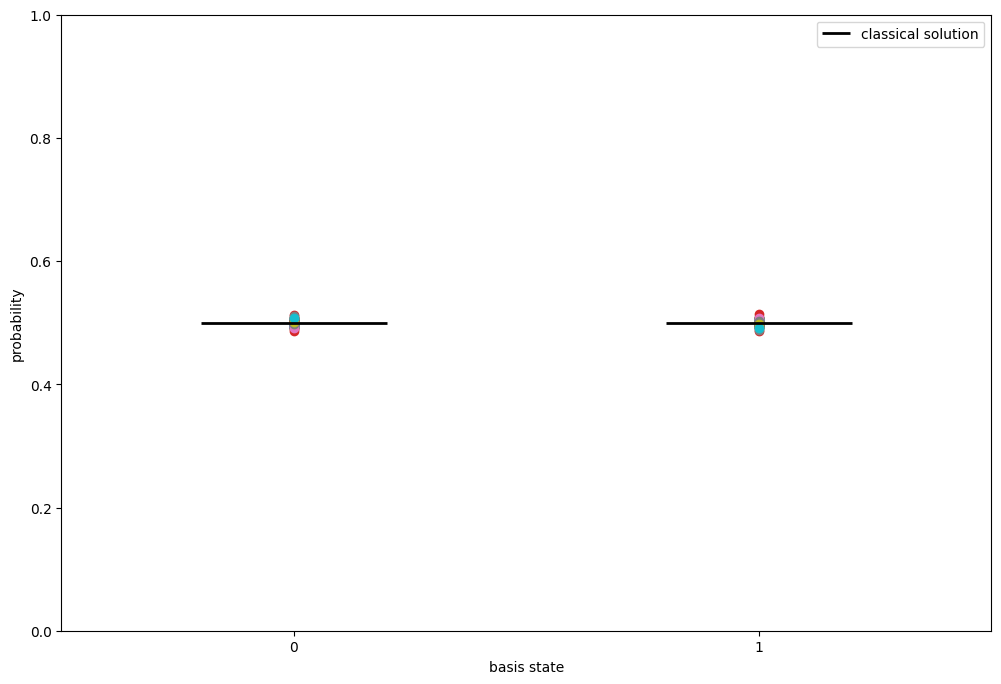

In [37]:
tests = 100

prob_list = []
for i in range(0, tests):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

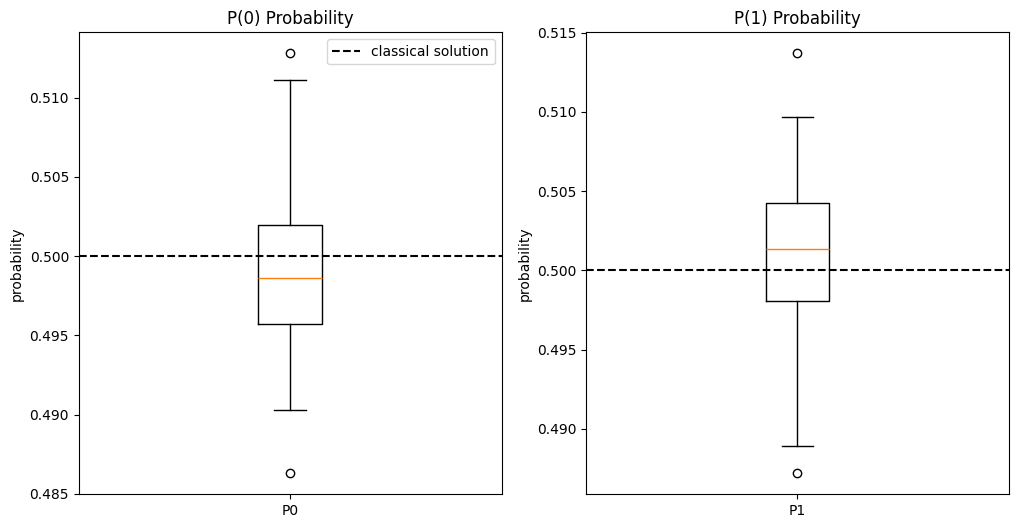

In [38]:
P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

# separate panel
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
# plt.tight_layout()
axes[0].set_title("P(0) Probability")
axes[1].set_title("P(1) Probability")
plt.show()

# testing 1 qubit vqls on a suite of real and then complex matrices

In [40]:
random_c = lambda: random.random() + 1j * random.random()
random_r = random.random

A = np.array([
    [random_c(), random_c()],
    [random_c(), random_c()]
])
b = 1/np.sqrt(2) * np.array([
    [1],
    [1]
])

print(A)
qres = vqls.solve(A, b).solution()#.reshape(-1, 1)
cres = np.linalg.solve(A,b)
print(f"Quantum Solution: \n{qres}\n")
print(f"Classical Solution: \n{cres}\n")

# difference as a metric of accuracy
print(f"Accuracy: {vqls.compute_accuracy(qres, cres)*100:.3f}%")

[[0.89195682+0.93077895j 0.58406196+0.64430381j]
 [0.61126622+0.20862512j 0.61470002+0.84079364j]]
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0003227397287758338
       x: [ 1.075e+00]
     nit: 32
   maxcv: 0.0
    nfev: 16
Quantum Solution: 
[[0.10021134-0.11253898j]
 [0.39598738-0.44470034j]]

Classical Solution: 
[[0.11890129-0.09423386j]
 [0.37377927-0.45790637j]]

Accuracy: 96.323%


In [ ]:
def res_diff(x, y):
    return 1 - np.linalg.norm(x-y)

def test_vqls(b=None, shots=30):
    Ai = [ # random data set of matrices
        np.array([
            [1, random_c()],
            [random_c(), random_c()]
        ]) for _ in range(shots)
    ]

    if b is None:
        b = 1/np.sqrt(2) * np.array([
            [1],
            [1]
        ])

    accuracies = []
    for A in Ai:
        # print(b)
        q_soln = vqls.solve(A, b).solution()
        c_soln = np.linalg.solve(A, b)
        # print(f"Quantum Solution: \n{q_soln}\n")
        # print(f"Classical Solution: \n{c_soln}\n")

        diff = res_diff(q_soln, c_soln)
        # print(f"Accuracy: {diff}")
        accuracies.append(diff)

    # print(accuracies)

    return accuracies

accuracies = test_vqls()
avg_diff = sum(accuracies) / len(accuracies)

print(f"Average Quantum Solution Accuracy: {avg_diff*100:.2f}%")

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.018555159297919954
       x: [ 1.175e+00]
     nit: 40
   maxcv: 0.0
    nfev: 18
Average Quantum Solution Accuracy: 68.50%


In [ ]:
avg_diff, accuracies

(np.float64(0.16704130875460665), [np.float64(0.16704130875460665)])

In [ ]:
# plt.plot(np.linspace(0, len(accuracies), 1), accuracies)
# plt.axhline(avg_diff, color='black', linestyle='--', label="Average")
# plt.ylabel("Accuracy")
# plt.xlabel("Test # (random matrix)")
# plt.title("Constant Top Right Entry")
# plt.legend()

[array([[0.65277234+0.j, 0.81518871+0.j],
       [0.78477174+0.j, 0.43220668+0.j]]), array([[0.21037977+0.j, 0.67947454+0.j],
       [0.53502578+0.j, 0.95176448+0.j]]), array([[0.84043963+0.j, 0.18224401+0.j],
       [0.30078863+0.j, 0.63571054+0.j]])]
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [-9.070e-01]
     nit: 38
   maxcv: 0.0
    nfev: 19
0.9999999992081279
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
 message: The lower bound for the trust-region radius 

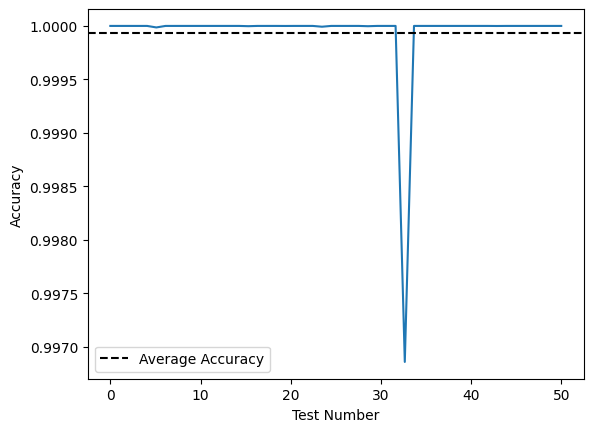

In [ ]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0, cost='direct')
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1, cost='direct')

data = vqls.generate_dataset(random_entries=[1+0j, 2+0j, 3+0j, 4+0j], shots=50)
print(data[:3])

# 1 param ansatz ry h
accuracies = vqls_ry.accuracy_test(data)
vqls_ry.plot_tests(accuracies)

direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.6653345369377348e-15
       x: [-9.070e-01 -6.387e-07]
     nit: 39
   maxcv: 0.0
    nfev: 33
0.9999998300629808
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct cost
direct c

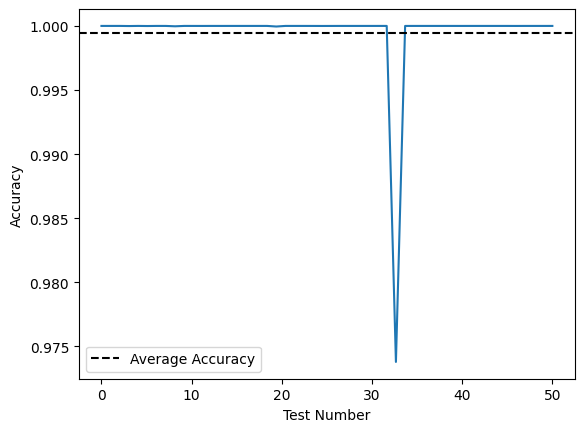

In [ ]:
# 2 param ansatz rz ry h
accuracies = vqls_rz.accuracy_test(data)
vqls_rz.plot_tests(accuracies)